In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 3.1.0
NumPy version: 2.5.4


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project folder
project_root = Path.cwd()

if not (project_root / "data" / "raw" / "elliptic").exists():
    project_root = project_root.parent

data_dir = project_root / "data" / "raw" / "elliptic"

# Load the three dataset files
features = pd.read_csv(
    data_dir / "elliptic_txs_features.csv",
    header=None
)

classes = pd.read_csv(
    data_dir / "elliptic_txs_classes.csv"
)

edges = pd.read_csv(
    data_dir / "elliptic_txs_edgelist.csv"
)

print("Dataset loaded successfully!")
print("Features:", features.shape)
print("Classes:", classes.shape)
print("Edges:", edges.shape)

Dataset loaded successfully!
Features: (203769, 167)
Classes: (203769, 2)
Edges: (234355, 2)


In [3]:
print("FEATURES")
display(features.head())

print("\nCLASSES")
display(classes.head())

print("\nEDGES")
display(edges.head())

print("\nCLASS DISTRIBUTION")
display(classes["class"].value_counts(dropna=False))

print("\nMISSING VALUES")
print("Features:", features.isna().sum().sum())
print("Classes:", classes.isna().sum().sum())
print("Edges:", edges.isna().sum().sum())

FEATURES


,0,1,2,3,4,5,6,7,8,9,...,157,158,159,160,161,162,163,164,165,166
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117



CLASSES


,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown



EDGES


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206



CLASS DISTRIBUTION


class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


MISSING VALUES
Features: 0
Classes: 0
Edges: 0


In [4]:
# Name the columns in the feature dataset
feature_columns = (
    ["txId", "time_step"] +
    [f"feature_{i}" for i in range(1, 166)]
)

features.columns = feature_columns

print("Feature columns assigned:", len(features.columns))
display(features.head())

Feature columns assigned: 167


,txId,time_step,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_156,feature_157,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


In [5]:
print("CLASS DISTRIBUTION")
print(classes["class"].value_counts(dropna=False))

print("\nMISSING VALUES")
print("Features:", features.isna().sum().sum())
print("Classes:", classes.isna().sum().sum())
print("Edges:", edges.isna().sum().sum())

print("\nDUPLICATE TRANSACTION IDs")
print("Features:", features["txId"].duplicated().sum())
print("Classes:", classes["txId"].duplicated().sum())

print("\nTIME STEP DISTRIBUTION")
print(features["time_step"].value_counts().sort_index())

print("\nNUMERICAL FEATURE SUMMARY")
display(features.iloc[:, 2:].describe().T.head(10))

CLASS DISTRIBUTION
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64

MISSING VALUES
Features: 0
Classes: 0
Edges: 0

DUPLICATE TRANSACTION IDs
Features: 0
Classes: 0

TIME STEP DISTRIBUTION
time_step
1     7880
2     4544
3     6621
4     5693
5     6803
6     4328
7     6048
8     4457
9     4996
10    6727
11    4296
12    2047
13    4528
14    2022
15    3639
16    2975
17    3385
18    1976
19    3506
20    4291
21    3537
22    5894
23    4165
24    4592
25    2314
26    2523
27    1089
28    1653
29    4275
30    2483
31    2816
32    4525
33    3151
34    2486
35    5507
36    6393
37    3306
38    2891
39    2760
40    4481
41    5342
42    7140
43    5063
44    4975
45    5598
46    3519
47    5121
48    2954
49    2454
Name: count, dtype: int64

NUMERICAL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
feature_1,203769.0,-8.926723e-18,1.000002,-0.172983,-0.172532,-0.169204,-0.131855,71.681966
feature_2,203769.0,0.000000e+00,1.000002,-0.210553,-0.180327,-0.132897,-0.055242,73.595052
feature_3,203769.0,3.570689e-17,1.000002,-1.756361,-1.201369,0.463609,1.018602,2.683580
feature_4,203769.0,9.205683e-18,1.000002,-0.121970,-0.121970,-0.121970,-0.121970,49.027598
feature_5,203769.0,1.227424e-17,1.000002,-0.063725,-0.043875,-0.043875,-0.043875,260.090707
feature_6,203769.0,1.673761e-17,1.000002,-0.113002,-0.113002,-0.113002,-0.113002,54.565178
feature_7,203769.0,-4.463361e-18,1.000002,-0.061584,-0.061584,-0.061584,-0.061584,113.440873
feature_8,203769.0,-4.463361e-18,1.000002,-0.163646,-0.163517,-0.162044,-0.135593,73.354565
feature_9,203769.0,8.926723e-18,1.000002,-0.169460,-0.169070,-0.166226,-0.132366,72.318396
feature_10,203769.0,-6.974002e-19,1.000002,-0.049707,-0.049707,-0.049707,-0.049707,189.186944


In [6]:
# Merge features and labels using transaction ID
data = features.merge(
    classes,
    on="txId",
    how="inner",
    validate="one_to_one"
)

# Keep transaction metadata separate
metadata = data[["txId", "time_step", "class"]].copy()

# Select only the 165 numerical features
X = data[[f"feature_{i}" for i in range(1, 166)]].copy()

# Keep labels separate for evaluation
y = data["class"].copy()

print("Prepared feature matrix:", X.shape)
print("Labels:", y.shape)
print("Metadata:", metadata.shape)

print("\nLabel distribution:")
print(y.value_counts())

Prepared feature matrix: (203769, 165)
Labels: (203769,)
Metadata: (203769, 3)

Label distribution:
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [7]:
# Select 10,000 transactions without using their labels
sample_size = 10000

X_sample = X.sample(
    n=sample_size,
    random_state=42
)

# Align labels and metadata with the sampled transactions
y_sample = y.loc[X_sample.index]
metadata_sample = metadata.loc[X_sample.index]

print("Sample shape:", X_sample.shape)
print("\nSample label distribution:")
print(y_sample.value_counts())

print("\nSample contains missing values:", X_sample.isna().sum().sum())

Sample shape: (10000, 165)

Sample label distribution:
class
unknown    7691
2          2059
1           250
Name: count, dtype: int64

Sample contains missing values: 0


In [8]:
from sklearn.ensemble import IsolationForest

# Isolation Forest — configuration 1
if_model_2 = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

if_predictions_2 = if_model_2.fit_predict(X_sample)

# Isolation Forest — configuration 2
if_model_5 = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

if_predictions_5 = if_model_5.fit_predict(X_sample)

# Convert predictions: 1 = normal, -1 = anomaly
print("Isolation Forest Results")
print("Contamination 2%:")
print(pd.Series(if_predictions_2).value_counts())

print("\nContamination 5%:")
print(pd.Series(if_predictions_5).value_counts())

Isolation Forest Results
Contamination 2%:
 1    9800
-1     200
Name: count, dtype: int64

Contamination 5%:
 1    9500
-1     500
Name: count, dtype: int64


In [9]:
from sklearn.neighbors import LocalOutlierFactor

# LOF — configuration 1
lof_model_20 = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.02,
    n_jobs=-1
)

lof_predictions_20 = lof_model_20.fit_predict(X_sample)

# LOF — configuration 2
lof_model_50 = LocalOutlierFactor(
    n_neighbors=50,
    contamination=0.05,
    n_jobs=-1
)

lof_predictions_50 = lof_model_50.fit_predict(X_sample)

print("LOF Results")
print("20 neighbours, 2% contamination:")
print(pd.Series(lof_predictions_20).value_counts())

print("\n50 neighbours, 5% contamination:")
print(pd.Series(lof_predictions_50).value_counts())

LOF Results
20 neighbours, 2% contamination:
 1    9800
-1     200
Name: count, dtype: int64

50 neighbours, 5% contamination:
 1    9500
-1     500
Name: count, dtype: int64


In [10]:
# LOF: 20 neighbours, 5% contamination
lof_model_20_5 = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    n_jobs=-1
)

lof_predictions_20_5 = lof_model_20_5.fit_predict(X_sample)


# LOF: 50 neighbours, 2% contamination
lof_model_50_2 = LocalOutlierFactor(
    n_neighbors=50,
    contamination=0.02,
    n_jobs=-1
)

lof_predictions_50_2 = lof_model_50_2.fit_predict(X_sample)

print("LOF 20 neighbours, 5%:", (lof_predictions_20_5 == -1).sum())
print("LOF 50 neighbours, 2%:", (lof_predictions_50_2 == -1).sum())

LOF 20 neighbours, 5%: 500
LOF 50 neighbours, 2%: 200


In [11]:
# Create a comparison DataFrame
results = pd.DataFrame(index=X_sample.index)

results["IF_2"] = if_predictions_2 == -1
results["IF_5"] = if_predictions_5 == -1

results["LOF_20_2"] = lof_predictions_20 == -1
results["LOF_20_5"] = lof_predictions_20_5 == -1

results["LOF_50_2"] = lof_predictions_50_2 == -1
results["LOF_50_5"] = lof_predictions_50 == -1

# Compare Isolation Forest and LOF at matching settings
for if_col, lof_col in [
    ("IF_2", "LOF_20_2"),
    ("IF_5", "LOF_20_5"),
    ("IF_5", "LOF_50_5")
]:
    both = (results[if_col] & results[lof_col]).sum()
    either = (results[if_col] | results[lof_col]).sum()

    print(f"\n{if_col} vs {lof_col}")
    print("Both flagged:", both)
    print("Either flagged:", either)
    print("Jaccard agreement:", round(both / either, 4) if either else 0)


IF_2 vs LOF_20_2
Both flagged: 19
Either flagged: 381
Jaccard agreement: 0.0499

IF_5 vs LOF_20_5
Both flagged: 66
Either flagged: 934
Jaccard agreement: 0.0707

IF_5 vs LOF_50_5
Both flagged: 71
Either flagged: 929
Jaccard agreement: 0.0764


In [12]:
from sklearn.metrics import classification_report, confusion_matrix

# Actual labels: 1 = illicit, 0 = licit
known_mask = y_sample.isin(["1", "2"])

y_true = (y_sample[known_mask] == "1").astype(int)

# Evaluate Isolation Forest at 2% contamination
y_pred = results.loc[known_mask, "IF_2"].astype(int)

print("Isolation Forest — 2% contamination")
print(confusion_matrix(y_true, y_pred))
print(classification_report(
    y_true,
    y_pred,
    target_names=["Licit", "Illicit"],
    zero_division=0
))

Isolation Forest — 2% contamination
[[1866  193]
 [ 250    0]]
              precision    recall  f1-score   support

       Licit       0.88      0.91      0.89      2059
     Illicit       0.00      0.00      0.00       250

    accuracy                           0.81      2309
   macro avg       0.44      0.45      0.45      2309
weighted avg       0.79      0.81      0.80      2309



In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

evaluation_rows = []

model_predictions = {
    "IF_2%": if_predictions_2,
    "IF_5%": if_predictions_5,
    "LOF_20_2%": lof_predictions_20,
    "LOF_20_5%": lof_predictions_20_5,
    "LOF_50_2%": lof_predictions_50_2,
    "LOF_50_5%": lof_predictions_50
}

for name, predictions in model_predictions.items():

    # Evaluate only transactions with known labels
    y_pred = (predictions[known_mask.to_numpy()] == -1).astype(int)

    evaluation_rows.append({
        "Model": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "Flagged Transactions": (predictions == -1).sum()
    })

evaluation = pd.DataFrame(evaluation_rows)

display(evaluation.round(4))

,Model,Precision,Recall,F1 Score,Flagged Transactions
0,IF_2%,0.0000,0.000,0.0000,200
1,IF_5%,0.0000,0.000,0.0000,500
2,LOF_20_2%,0.0781,0.020,0.0318,200
3,LOF_20_5%,0.0452,0.036,0.0401,500
4,LOF_50_2%,0.0571,0.016,0.0250,200
5,LOF_50_5%,0.0437,0.032,0.0370,500


In [14]:
for name, predictions in model_predictions.items():

    y_pred = (predictions[known_mask.to_numpy()] == -1).astype(int)

    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name}")
    print("True positives:", cm[1, 1])
    print("False positives:", cm[0, 1])
    print("False negatives:", cm[1, 0])


IF_2%
True positives: 0
False positives: 193
False negatives: 250

IF_5%
True positives: 0
False positives: 409
False negatives: 250

LOF_20_2%
True positives: 5
False positives: 59
False negatives: 245

LOF_20_5%
True positives: 9
False positives: 190
False negatives: 241

LOF_50_2%
True positives: 4
False positives: 66
False negatives: 246

LOF_50_5%
True positives: 8
False positives: 175
False negatives: 242


In [15]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce 165 features to 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_sample)

print("Original feature dimensions:", X_sample.shape[1])
print("Reduced dimensions:", X_pca.shape[1])

print(
    "Explained variance by first two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original feature dimensions: 165
Reduced dimensions: 2
Explained variance by first two components: 17.25 %


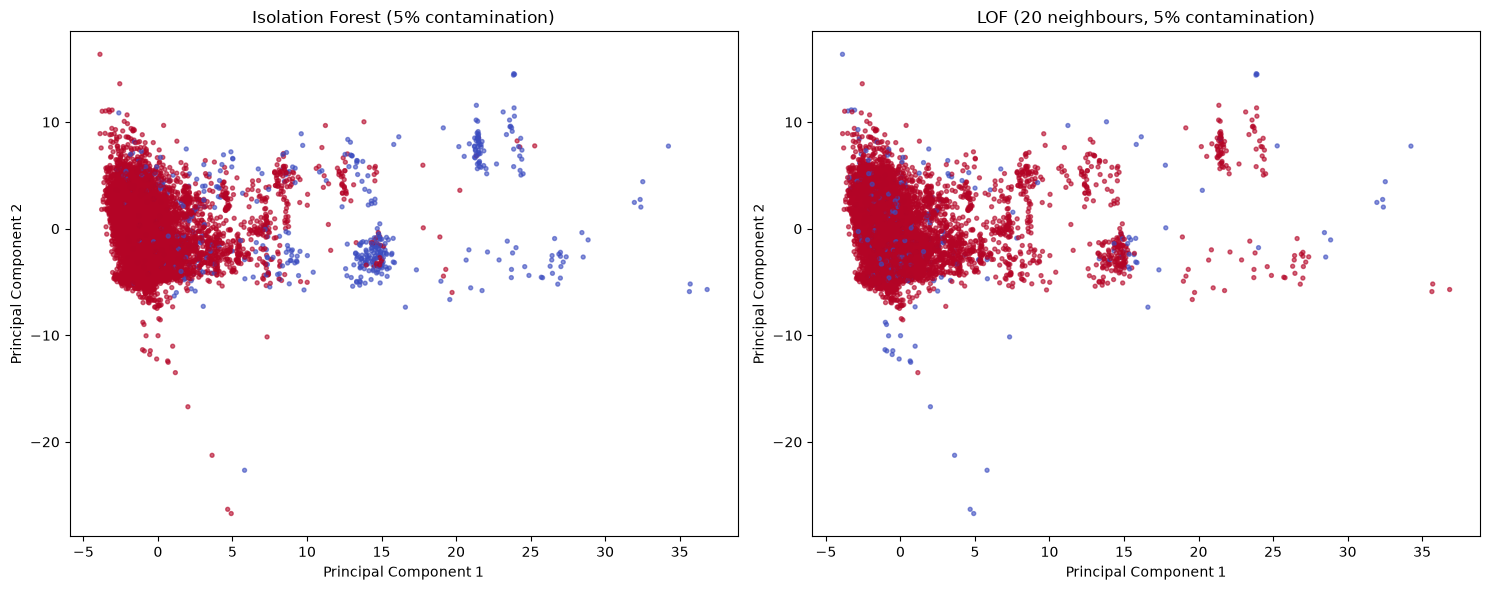

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Isolation Forest
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=if_predictions_5,
    cmap="coolwarm",
    s=8,
    alpha=0.6
)

axes[0].set_title("Isolation Forest (5% contamination)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# LOF
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=lof_predictions_20_5,
    cmap="coolwarm",
    s=8,
    alpha=0.6
)

axes[1].set_title("LOF (20 neighbours, 5% contamination)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

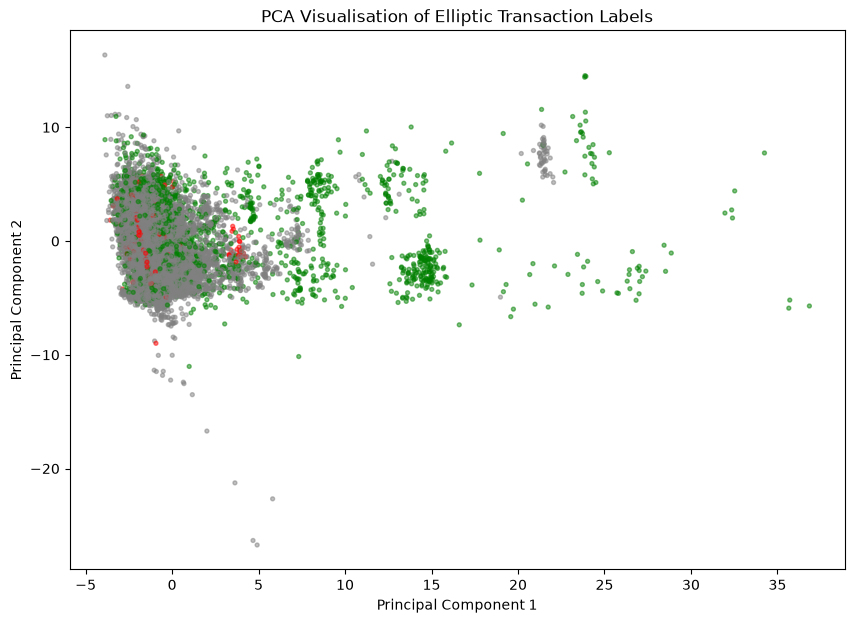

In [17]:
plt.figure(figsize=(10, 7))

label_colours = y_sample.map({
    "1": "red",
    "2": "green",
    "unknown": "gray"
})

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=label_colours,
    s=8,
    alpha=0.5
)

plt.title("PCA Visualisation of Elliptic Transaction Labels")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [18]:
from pathlib import Path

# Find project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

plots_dir = project_root / "results" / "plots"
metrics_dir = project_root / "results" / "metrics"

plots_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)

print("Results folders ready!")

Results folders ready!


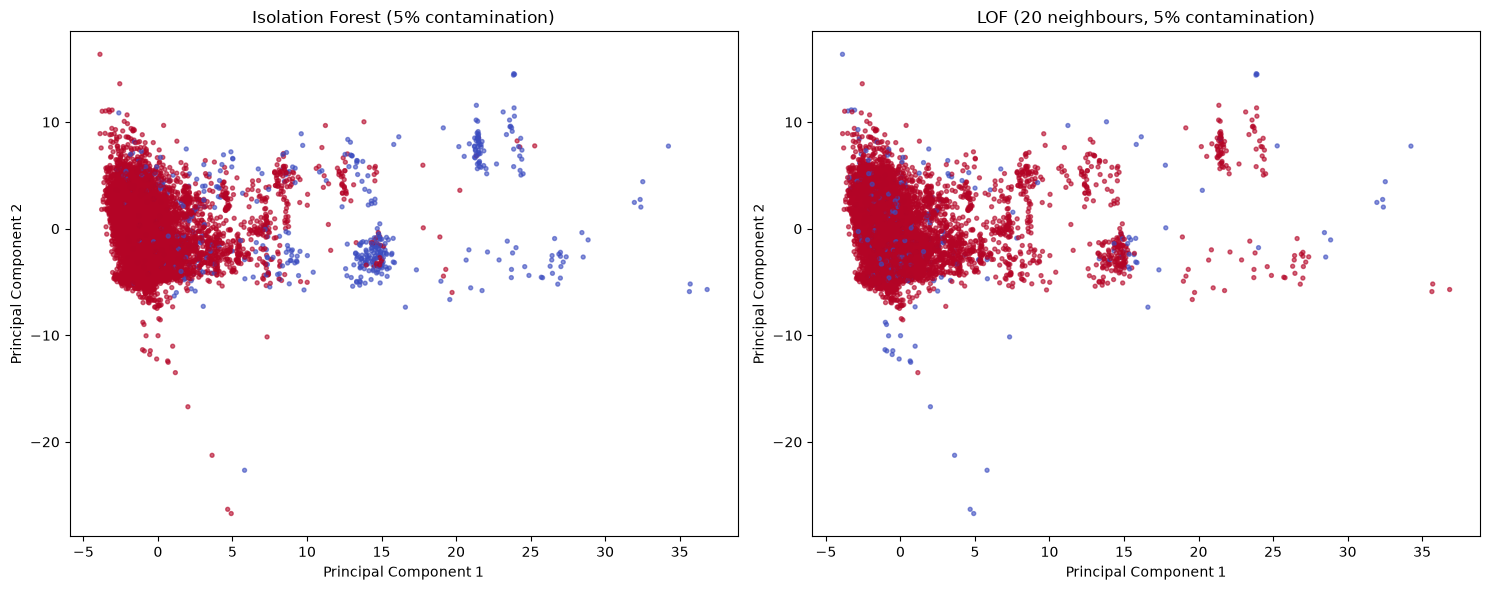

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=if_predictions_5,
    cmap="coolwarm", s=8, alpha=0.6
)
axes[0].set_title("Isolation Forest (5% contamination)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=lof_predictions_20_5,
    cmap="coolwarm", s=8, alpha=0.6
)
axes[1].set_title("LOF (20 neighbours, 5% contamination)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()

fig.savefig(
    plots_dir / "anomaly_detection_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

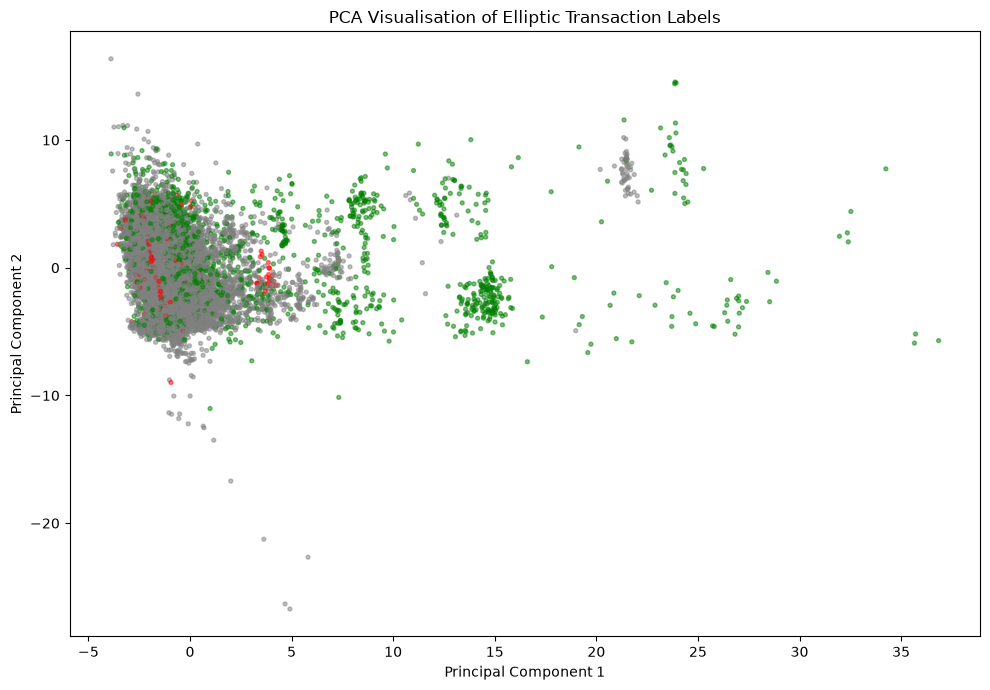

In [20]:
fig, ax = plt.subplots(figsize=(10, 7))

label_colours = y_sample.map({
    "1": "red",
    "2": "green",
    "unknown": "gray"
})

ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=label_colours,
    s=8,
    alpha=0.5
)

ax.set_title("PCA Visualisation of Elliptic Transaction Labels")
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")

plt.tight_layout()

fig.savefig(
    plots_dir / "pca_transaction_labels.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
evaluation.to_csv(
    metrics_dir / "model_evaluation.csv",
    index=False
)

print("Evaluation metrics saved successfully!")

Evaluation metrics saved successfully!


In [22]:
print("SAVED PLOT FILES:")
for file in plots_dir.iterdir():
    print(file.name)

print("\nSAVED METRIC FILES:")
for file in metrics_dir.iterdir():
    print(file.name)

SAVED PLOT FILES:
anomaly_detection_comparison.png
pca_enriched_features.png
pca_transaction_labels.png

SAVED METRIC FILES:
enriched_model_evaluation.csv
enriched_transaction_anomaly_flags.csv
false_positive_summary.csv
model_agreement.csv
model_evaluation.csv
original_vs_enriched_comparison.csv
pca_variance_comparison.csv
transaction_anomaly_flags.csv


In [23]:
# Calculate Jaccard similarity between every pair of models

model_names = results.columns.tolist()

jaccard_matrix = pd.DataFrame(
    index=model_names,
    columns=model_names,
    dtype=float
)

for model_a in model_names:
    for model_b in model_names:

        intersection = (
            results[model_a] & results[model_b]
        ).sum()

        union = (
            results[model_a] | results[model_b]
        ).sum()

        jaccard_matrix.loc[model_a, model_b] = (
            intersection / union if union > 0 else 0
        )

display(jaccard_matrix.round(3))

,IF_2,IF_5,LOF_20_2,LOF_20_5,LOF_50_2,LOF_50_5
IF_2,1.000,0.400,0.050,0.051,0.042,0.042
IF_5,0.400,1.000,0.042,0.071,0.043,0.076
LOF_20_2,0.050,0.042,1.000,0.400,0.481,0.365
LOF_20_5,0.051,0.071,0.400,1.000,0.308,0.447
LOF_50_2,0.042,0.043,0.481,0.308,1.000,0.400
LOF_50_5,0.042,0.076,0.365,0.447,0.400,1.000


In [24]:
print("Results:", results.shape)
print("Sample:", X_sample.shape)
print("Evaluation:", evaluation.shape)

Results: (10000, 6)
Sample: (10000, 165)
Evaluation: (6, 5)


In [25]:
# Save model evaluation metrics
evaluation.to_csv(
    metrics_dir / "model_evaluation.csv",
    index=False
)

# Save agreement matrix
jaccard_matrix.to_csv(
    metrics_dir / "model_agreement.csv"
)

print("Evaluation and agreement results saved.")

Evaluation and agreement results saved.


In [26]:
# Combine transaction metadata and anomaly predictions
anomaly_review = metadata_sample.copy()

for column in results.columns:
    anomaly_review[column + "_anomaly"] = results[column]

anomaly_review.to_csv(
    metrics_dir / "transaction_anomaly_flags.csv",
    index=False
)

print("Transaction-level anomaly results saved.")
display(anomaly_review.head())

Transaction-level anomaly results saved.


,txId,time_step,class,IF_2_anomaly,IF_5_anomaly,LOF_20_2_anomaly,LOF_20_5_anomaly,LOF_50_2_anomaly,LOF_50_5_anomaly
196048,205648424,47,unknown,False,False,False,False,False,False
16006,246059485,3,unknown,False,False,False,False,False,False
26188,209250952,5,unknown,False,False,False,False,False,False
28018,224242088,5,unknown,False,False,False,False,False,False
139710,70438228,35,unknown,False,False,False,False,False,False


In [27]:
known_mask = y_sample.isin(["1", "2"])

false_positive_summary = pd.DataFrame(index=results.columns)

for model in results.columns:
    false_positive_summary.loc[model, "Licit_flagged"] = (
        results.loc[known_mask & (y_sample == "2"), model].sum()
    )

    false_positive_summary.loc[model, "Illicit_flagged"] = (
        results.loc[known_mask & (y_sample == "1"), model].sum()
    )

    false_positive_summary.loc[model, "Unknown_flagged"] = (
        results.loc[y_sample == "unknown", model].sum()
    )

display(false_positive_summary.astype(int))

,Licit_flagged,Illicit_flagged,Unknown_flagged
IF_2,193,0,7
IF_5,409,0,91
LOF_20_2,59,5,136
LOF_20_5,190,9,301
LOF_50_2,66,4,130
LOF_50_5,175,8,317


In [28]:
false_positive_summary.to_csv(
    metrics_dir / "false_positive_summary.csv"
)

### False-Positive Analysis and Responsible Interpretation

The results show differences in detection behaviour between Isolation Forest and Local Outlier Factor (LOF). Neither Isolation Forest configuration identified any labelled illicit transactions in the 10,000-transaction sample. LOF identified a small number, ranging from 4 to 9 transactions across the tested configurations.

The LOF configuration with 20 neighbours and 5% contamination detected the largest number of labelled illicit transactions (9 out of 250). However, it also flagged 190 transactions labelled licit. This illustrates the trade-off between identifying more labelled illicit observations and generating potential false alarms.

A flagged transaction should not automatically be interpreted as illicit activity. The models identify statistical irregularities in the selected features, not criminal intent or confirmed financial crime. Furthermore, the dataset contains many transactions with unknown labels, so their actual status cannot be determined through label-based evaluation.

In practical financial monitoring, false positives may result in unnecessary investigations, additional operational costs, and unfair suspicion of legitimate activity. Therefore, anomaly scores should be treated as indicators for further examination rather than independent grounds for accusations or enforcement action.

These findings are limited to the selected 10,000-transaction sample, its available features, and the tested parameter settings. The results do not establish that either method is universally ineffective or reliable.

In [29]:
print("Edge list shape:", edges.shape)
display(edges.head())
print("Columns:", edges.columns.tolist())

Edge list shape: (234355, 2)


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


Columns: ['txId1', 'txId2']


In [30]:
# Count outgoing and incoming transaction connections

outgoing = edges.groupby("txId1").size()
incoming = edges.groupby("txId2").size()

# Create a transaction-level connectivity dataframe

graph_features = pd.DataFrame(index=features["txId"])

graph_features.index.name = "txId"

graph_features["outgoing_connections"] = (
    graph_features.index.map(outgoing).fillna(0)
)

graph_features["incoming_connections"] = (
    graph_features.index.map(incoming).fillna(0)
)

graph_features["total_connections"] = (
    graph_features["outgoing_connections"]
    + graph_features["incoming_connections"]
)

graph_features = graph_features.reset_index()

display(graph_features.head())
print("Graph feature shape:", graph_features.shape)

,txId,outgoing_connections,incoming_connections,total_connections
0,230425980,1.0,1.0,2.0
1,5530458,1.0,1.0,2.0
2,232022460,2.0,1.0,3.0
3,232438397,1.0,160.0,161.0
4,230460314,8.0,2.0,10.0


Graph feature shape: (203769, 4)


In [31]:
display(
    graph_features[
        ["incoming_connections", "outgoing_connections", "total_connections"]
    ].describe()
)

print("Missing values:")
display(graph_features.isnull().sum())

,incoming_connections,outgoing_connections,total_connections
count,203769.000000,203769.000000,203769.000000
mean,1.150101,1.150101,2.300203
std,3.911132,1.894740,4.328377
min,0.000000,0.000000,1.000000
25%,0.000000,1.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,1.000000,1.000000,2.000000
max,284.000000,472.000000,473.000000


Missing values:


txId                    0
outgoing_connections    0
incoming_connections    0
total_connections       0
dtype: int64

In [32]:
from sklearn.preprocessing import StandardScaler

# Match graph features to the exact 10,000 sampled transactions
graph_sample = (
    graph_features
    .set_index("txId")
    .loc[
        metadata_sample["txId"],
        ["incoming_connections", "outgoing_connections"]
    ]
    .copy()
)

# Preserve the original sample index
graph_sample.index = X_sample.index

# Reduce skewness in graph connectivity counts
graph_log = np.log1p(graph_sample)

# Standardise the two graph features
graph_scaler = StandardScaler()
graph_scaled = pd.DataFrame(
    graph_scaler.fit_transform(graph_log),
    columns=["incoming_connections_scaled",
             "outgoing_connections_scaled"],
    index=X_sample.index
)

# Combine original and graph-derived features
X_enriched = pd.concat([X_sample, graph_scaled], axis=1)

print("Original feature shape:", X_sample.shape)
print("Enriched feature shape:", X_enriched.shape)
print("Missing values:", X_enriched.isnull().sum().sum())

display(X_enriched.head())

Original feature shape: (10000, 165)
Enriched feature shape: (10000, 167)
Missing values: 0


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_158,feature_159,feature_160,feature_161,feature_162,feature_163,feature_164,feature_165,incoming_connections_scaled,outgoing_connections_scaled
196048,-0.172914,0.017225,1.018602,-0.12197,-0.043875,-0.113002,-0.061584,-0.163570,-0.169385,-0.049707,...,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,0.235785,-1.677265
16006,2.277955,-0.132897,-1.201369,-0.12197,-0.043875,-0.113002,-0.061584,2.344026,2.303067,-0.049707,...,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,0.235785,0.046090
26188,-0.169374,-0.184668,-1.201369,-0.12197,-0.043875,-0.113002,-0.061584,-0.159953,-0.165819,-0.049707,...,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,0.235785,0.046090
28018,-0.161208,-0.194918,-0.091383,-0.12197,-0.043875,-0.113002,-0.061584,-0.151598,-0.157581,-0.049707,...,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,-1.232047,0.046090
139710,0.543231,-0.124050,1.018602,-0.12197,-0.043875,-0.113002,-0.061584,0.569149,0.553064,-0.049707,...,0.241128,0.241406,0.135448,-0.068266,-0.131155,-0.011377,-0.120613,-0.119792,0.235785,0.046090


In [33]:
from sklearn.ensemble import IsolationForest

# Isolation Forest on graph-enriched features
if_enriched_2 = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

if_enriched_5 = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

if_enriched_pred_2 = if_enriched_2.fit_predict(X_enriched)
if_enriched_pred_5 = if_enriched_5.fit_predict(X_enriched)

print("Isolation Forest — enriched features")
print("2% anomalies:", (if_enriched_pred_2 == -1).sum())
print("5% anomalies:", (if_enriched_pred_5 == -1).sum())

Isolation Forest — enriched features
2% anomalies: 200
5% anomalies: 500


In [34]:
from sklearn.neighbors import LocalOutlierFactor

lof_enriched_predictions = {}

for neighbours in [20, 50]:
    for contamination in [0.02, 0.05]:

        model = LocalOutlierFactor(
            n_neighbors=neighbours,
            contamination=contamination,
            n_jobs=-1
        )

        predictions = model.fit_predict(X_enriched)

        key = f"LOF_{neighbours}_{int(contamination * 100)}"
        lof_enriched_predictions[key] = predictions

        print(
            key,
            "anomalies:",
            (predictions == -1).sum()
        )

LOF_20_2 anomalies: 200
LOF_20_5 anomalies: 500
LOF_50_2 anomalies: 200
LOF_50_5 anomalies: 500


In [35]:
enriched_results = pd.DataFrame(index=X_enriched.index)

enriched_results["IF_2"] = if_enriched_pred_2 == -1
enriched_results["IF_5"] = if_enriched_pred_5 == -1

for name, predictions in lof_enriched_predictions.items():
    enriched_results[name] = predictions == -1

display(enriched_results.sum())

IF_2        200
IF_5        500
LOF_20_2    200
LOF_20_5    500
LOF_50_2    200
LOF_50_5    500
dtype: int64

In [36]:
comparison_rows = []

for model in results.columns:
    original_flags = results[model]
    enriched_flags = enriched_results[model]

    intersection = (original_flags & enriched_flags).sum()
    union = (original_flags | enriched_flags).sum()

    comparison_rows.append({
        "Model": model,
        "Original_flagged": int(original_flags.sum()),
        "Enriched_flagged": int(enriched_flags.sum()),
        "Same_transactions": int(intersection),
        "Jaccard_similarity": round(
            intersection / union if union else 0, 4
        )
    })

feature_comparison = pd.DataFrame(comparison_rows)
display(feature_comparison)

,Model,Original_flagged,Enriched_flagged,Same_transactions,Jaccard_similarity
0,IF_2,200,200,181,0.8265
1,IF_5,500,500,438,0.7794
2,LOF_20_2,200,200,163,0.6878
3,LOF_20_5,500,500,421,0.7271
4,LOF_50_2,200,200,167,0.7167
5,LOF_50_5,500,500,430,0.7544


In [37]:
from sklearn.metrics import precision_score, recall_score, f1_score

known_mask = y_sample.isin(["1", "2"])
y_true = (y_sample[known_mask] == "1").astype(int)

enriched_evaluation = []

for model in enriched_results.columns:
    y_pred = enriched_results.loc[known_mask, model].astype(int)

    enriched_evaluation.append({
        "Model": model,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1_score": f1_score(y_true, y_pred, zero_division=0),
        "Flagged_total": int(enriched_results[model].sum())
    })

enriched_evaluation = pd.DataFrame(enriched_evaluation)
display(enriched_evaluation.round(4))

,Model,Precision,Recall,F1_score,Flagged_total
0,IF_2,0.0000,0.000,0.0000,200
1,IF_5,0.0000,0.000,0.0000,500
2,LOF_20_2,0.0533,0.016,0.0246,200
3,LOF_20_5,0.0461,0.040,0.0428,500
4,LOF_50_2,0.0575,0.020,0.0297,200
5,LOF_50_5,0.0332,0.028,0.0304,500


In [38]:
enriched_results = pd.DataFrame(index=X_enriched.index)

enriched_results["IF_2"] = if_enriched_pred_2 == -1
enriched_results["IF_5"] = if_enriched_pred_5 == -1

for name, predictions in lof_enriched_predictions.items():
    enriched_results[name] = predictions == -1

display(enriched_results.sum())

IF_2        200
IF_5        500
LOF_20_2    200
LOF_20_5    500
LOF_50_2    200
LOF_50_5    500
dtype: int64

In [39]:
comparison_rows = []

for model in results.columns:
    original_flags = results[model]
    enriched_flags = enriched_results[model]

    intersection = (original_flags & enriched_flags).sum()
    union = (original_flags | enriched_flags).sum()

    comparison_rows.append({
        "Model": model,
        "Original_flagged": int(original_flags.sum()),
        "Enriched_flagged": int(enriched_flags.sum()),
        "Same_transactions": int(intersection),
        "Jaccard_similarity": round(
            intersection / union if union else 0, 4
        )
    })

feature_comparison = pd.DataFrame(comparison_rows)
display(feature_comparison)

,Model,Original_flagged,Enriched_flagged,Same_transactions,Jaccard_similarity
0,IF_2,200,200,181,0.8265
1,IF_5,500,500,438,0.7794
2,LOF_20_2,200,200,163,0.6878
3,LOF_20_5,500,500,421,0.7271
4,LOF_50_2,200,200,167,0.7167
5,LOF_50_5,500,500,430,0.7544


In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score

known_mask = y_sample.isin(["1", "2"])
y_true = (y_sample[known_mask] == "1").astype(int)

enriched_evaluation = []

for model in enriched_results.columns:
    y_pred = enriched_results.loc[known_mask, model].astype(int)

    enriched_evaluation.append({
        "Model": model,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1_score": f1_score(y_true, y_pred, zero_division=0),
        "Flagged_total": int(enriched_results[model].sum())
    })

enriched_evaluation = pd.DataFrame(enriched_evaluation)
display(enriched_evaluation.round(4))

,Model,Precision,Recall,F1_score,Flagged_total
0,IF_2,0.0000,0.000,0.0000,200
1,IF_5,0.0000,0.000,0.0000,500
2,LOF_20_2,0.0533,0.016,0.0246,200
3,LOF_20_5,0.0461,0.040,0.0428,500
4,LOF_50_2,0.0575,0.020,0.0297,200
5,LOF_50_5,0.0332,0.028,0.0304,500


In [41]:
# Save enriched model evaluation
enriched_evaluation.to_csv(
    project_root / "results" / "metrics" / "enriched_model_evaluation.csv",
    index=False
)

# Save original vs enriched comparison
feature_comparison.to_csv(
    project_root / "results" / "metrics" / "original_vs_enriched_comparison.csv",
    index=False
)

# Save transaction-level enriched anomaly flags
enriched_flags_output = pd.concat(
    [
        metadata_sample.reset_index(drop=True),
        enriched_results.reset_index(drop=True)
    ],
    axis=1
)

enriched_flags_output.to_csv(
    project_root / "results" / "metrics" / "enriched_transaction_anomaly_flags.csv",
    index=False
)

print("Enriched results saved successfully.")

Enriched results saved successfully.


In [42]:
from sklearn.decomposition import PCA

# PCA on enriched features
pca_enriched = PCA(n_components=2, random_state=42)
X_enriched_pca = pca_enriched.fit_transform(X_enriched)

print(
    "Enriched PCA explained variance:",
    round(pca_enriched.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Enriched PCA explained variance: 17.03 %


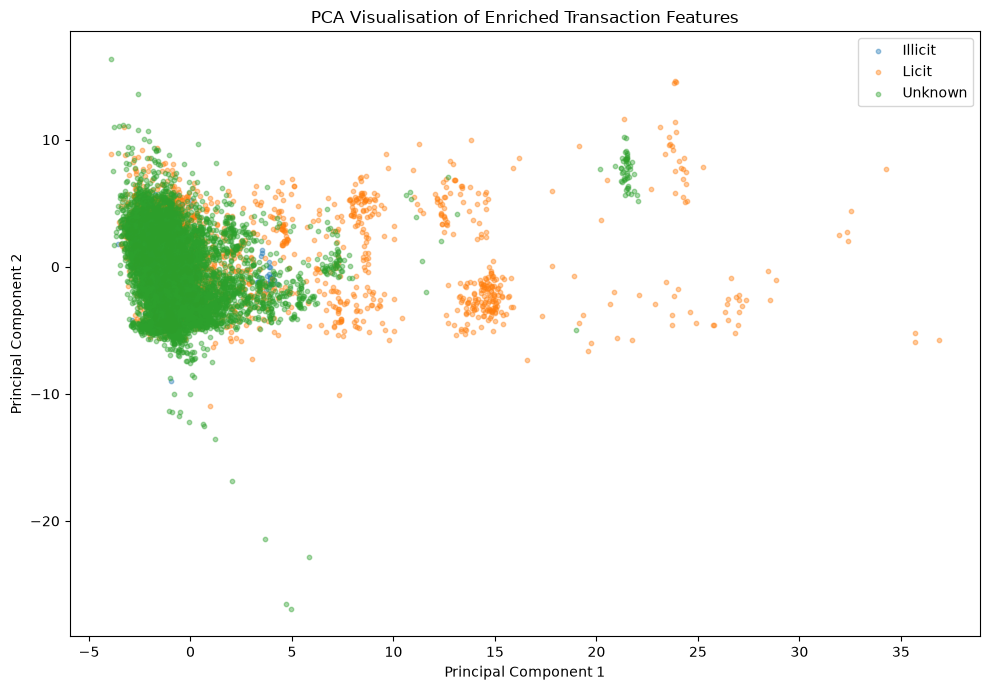

In [ ]:
plt.figure(figsize=(10, 7))

for label, name in [("1", "Illicit"), ("2", "Licit"), ("unknown", "Unknown")]:
    mask = (y_sample == label).to_numpy()

    plt.scatter(
        X_enriched_pca[mask, 0],
        X_enriched_pca[mask, 1],
        label=name,
        alpha=0.4,
        s=10
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualisation of Enriched Transaction Features")
plt.legend()
plt.tight_layout()

plt.savefig(
    project_root / "results" / "plots" / "pca_enriched_features.png",
    dpi=300
)

plt.show()

In [ ]:
pca_comparison = pd.DataFrame({
    "Feature_Set": ["Original (165 features)", "Enriched (167 features)"],
    "Explained_Variance": [
        pca.explained_variance_ratio_.sum(),
        pca_enriched.explained_variance_ratio_.sum()
    ]
})

pca_comparison["Explained_Variance_Percent"] = (
    pca_comparison["Explained_Variance"] * 100
).round(2)

display(pca_comparison)

pca_comparison.to_csv(
    project_root / "results" / "metrics" / "pca_variance_comparison.csv",
    index=False
)

,Feature_Set,Explained_Variance,Explained_Variance_Percent
0,Original (165 features),0.172503,17.25
1,Enriched (167 features),0.170318,17.03


In [ ]:
expected_files = [
    "model_evaluation.csv",
    "model_agreement.csv",
    "transaction_anomaly_flags.csv",
    "false_positive_summary.csv",
    "enriched_model_evaluation.csv",
    "original_vs_enriched_comparison.csv",
    "enriched_transaction_anomaly_flags.csv",
    "pca_variance_comparison.csv"
]

metrics_dir = project_root / "results" / "metrics"

for filename in expected_files:
    file_path = metrics_dir / filename
    print(
        filename,
        "— FOUND" if file_path.exists() else "— MISSING"
    )

model_evaluation.csv — FOUND
model_agreement.csv — FOUND
transaction_anomaly_flags.csv — FOUND
false_positive_summary.csv — FOUND
enriched_model_evaluation.csv — FOUND
original_vs_enriched_comparison.csv — FOUND
enriched_transaction_anomaly_flags.csv — FOUND
pca_variance_comparison.csv — FOUND


In [ ]:
plots_dir = project_root / "results" / "plots"

expected_plots = [
    "anomaly_detection_comparison.png",
    "pca_transaction_labels.png",
    "pca_enriched_features.png"
]

for filename in expected_plots:
    file_path = plots_dir / filename
    print(
        filename,
        "— FOUND" if file_path.exists() else "— MISSING"
    )

anomaly_detection_comparison.png — FOUND
pca_transaction_labels.png — FOUND
pca_enriched_features.png — FOUND
